In [1]:
import sys

print(sys.executable)

c:\Users\bhaga\OneDrive\Documents\Study Materials\spyder_py\MLProject\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

In [3]:
from pathlib import Path

# Locate the project directory
project_dir = Path.cwd()

if project_dir.name == "Notebooks":
    project_dir = project_dir.parent

# Dataset path
file_path = project_dir / "Data" / "interim" / "railway_sample_10_percent.parquet"

# Load dataset into pandas DataFrame
df = pd.read_parquet(file_path)

print("Dataset loaded successfully!")


# Display first five rows
display(df.head())

# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Dataset information
df.info()

Dataset loaded successfully!


,train_number,train_name,category,start_date,status,seq,station_code,scheduled_arrival,scheduled_departure,actual_arrival,actual_departure,arrival_reported,departure_reported,arrival_delay_min,departure_delay_min,run_quality
0,00762,NZM-RU,PEXP,2026-10-07,completed,1,NZM,NaT,2026-10-06 21:30:00+00:00,NaT,2026-10-06 22:39:00+00:00,False,True,NaN,69.0,0.9
1,00762,NZM-RU,PEXP,2026-10-07,completed,2,TKD,2026-10-06 21:50:00+00:00,2026-10-06 22:00:00+00:00,2026-10-06 22:56:00+00:00,2026-10-06 22:56:00+00:00,True,True,66.0,56.0,0.9
2,00762,NZM-RU,PEXP,2026-10-07,completed,3,BPL,2026-10-07 13:30:00+00:00,2026-10-07 13:35:00+00:00,2026-10-07 14:39:00+00:00,2026-10-07 14:49:00+00:00,True,True,69.0,74.0,0.9
3,00762,NZM-RU,PEXP,2026-10-07,completed,4,NGP,2026-10-07 23:20:00+00:00,2026-10-08 00:40:00+00:00,2026-10-07 21:24:00+00:00,NaT,True,False,-116.0,NaN,0.9
4,00762,NZM-RU,PEXP,2026-10-07,completed,5,BZA,2026-10-08 10:35:00+00:00,2026-10-08 10:55:00+00:00,2026-10-08 17:38:00+00:00,2026-10-08 18:33:00+00:00,True,True,423.0,458.0,0.9


Dataset shape: (645764, 16)

Column names:
['train_number', 'train_name', 'category', 'start_date', 'status', 'seq', 'station_code', 'scheduled_arrival', 'scheduled_departure', 'actual_arrival', 'actual_departure', 'arrival_reported', 'departure_reported', 'arrival_delay_min', 'departure_delay_min', 'run_quality']
<class 'pandas.DataFrame'>
RangeIndex: 645764 entries, 0 to 645763
Data columns (total 16 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   train_number         645764 non-null  str                
 1   train_name           645764 non-null  str                
 2   category             645764 non-null  str                
 3   start_date           645764 non-null  object             
 4   status               645764 non-null  str                
 5   seq                  645764 non-null  int16              
 6   station_code         645764 non-null  str                
 7   scheduled_ar

In [4]:
# Identify the first station of each train run
first_station = (
    df.groupby(["train_number", "start_date"])["seq"]
    .transform("min")
)

# Prepare the initial modeling dataset
model_df = df[
    (df["status"] == "completed") &
    (df["seq"] > first_station) &
    (df["arrival_delay_min"].notna())
].copy()

model_df = model_df.reset_index(drop=True)

print("Modeling dataset created successfully!")
print("Shape:", model_df.shape)

display(model_df.head())


print("Total records:", len(model_df))

print(
    "Unique train runs:",
    model_df[["train_number", "start_date"]]
    .drop_duplicates()
    .shape[0]
)

print("Unique trains:", model_df["train_number"].nunique())

print(
    "Average arrival delay:",
    model_df["arrival_delay_min"].mean().round(2)
)


Modeling dataset created successfully!
Shape: (398575, 16)


,train_number,train_name,category,start_date,status,seq,station_code,scheduled_arrival,scheduled_departure,actual_arrival,actual_departure,arrival_reported,departure_reported,arrival_delay_min,departure_delay_min,run_quality
0,00762,NZM-RU,PEXP,2026-10-07,completed,2,TKD,2026-10-06 21:50:00+00:00,2026-10-06 22:00:00+00:00,2026-10-06 22:56:00+00:00,2026-10-06 22:56:00+00:00,True,True,66.0,56.0,0.9
1,00762,NZM-RU,PEXP,2026-10-07,completed,3,BPL,2026-10-07 13:30:00+00:00,2026-10-07 13:35:00+00:00,2026-10-07 14:39:00+00:00,2026-10-07 14:49:00+00:00,True,True,69.0,74.0,0.9
2,00762,NZM-RU,PEXP,2026-10-07,completed,4,NGP,2026-10-07 23:20:00+00:00,2026-10-08 00:40:00+00:00,2026-10-07 21:24:00+00:00,NaT,True,False,-116.0,NaN,0.9
3,00762,NZM-RU,PEXP,2026-10-07,completed,5,BZA,2026-10-08 10:35:00+00:00,2026-10-08 10:55:00+00:00,2026-10-08 17:38:00+00:00,2026-10-08 18:33:00+00:00,True,True,423.0,458.0,0.9
4,00762,NZM-RU,PEXP,2026-10-07,completed,6,RU,2026-10-08 22:35:00+00:00,NaT,2026-10-09 02:49:00+00:00,NaT,True,False,254.0,NaN,0.9


Total records: 398575
Unique train runs: 32121
Unique trains: 9140
Average arrival delay: 37.77


In [5]:
# Count unusually early and late arrivals

extreme_counts = pd.Series({
    "More than 3 hours early :":
        (model_df["arrival_delay_min"] < -180).sum(),

    "More than 1 hour early :":
        (model_df["arrival_delay_min"] < -60).sum(),

    "More than 3 hours late :":
        (model_df["arrival_delay_min"] > 180).sum(),

    "More than 6 hours late :":
        (model_df["arrival_delay_min"] > 360).sum(),

    "More than 12 hours late :":
        (model_df["arrival_delay_min"] > 720).sum()
})

display(extreme_counts)

More than 3 hours early :      126
More than 1 hour early :       253
More than 3 hours late :     15612
More than 6 hours late :      4258
More than 12 hours late :      702
dtype: int64

In [6]:
# 10 earliest arrivals
display(
    model_df.nsmallest(
        10, "arrival_delay_min"
    )[
        [
            "train_number",
            "train_name",
            "start_date",
            "seq",
            "station_code",
            "scheduled_arrival",
            "actual_arrival",
            "arrival_delay_min"
        ]
    ]
)

# 10 latest arrivals
display(
    model_df.nlargest(
        10, "arrival_delay_min"
    )[
        [
            "train_number",
            "train_name",
            "start_date",
            "seq",
            "station_code",
            "scheduled_arrival",
            "actual_arrival",
            "arrival_delay_min"
        ]
    ]
)

,train_number,train_name,start_date,seq,station_code,scheduled_arrival,actual_arrival,arrival_delay_min
224135,22724,SGNR NED SF EXP,2026-10-31,10,JU,2026-11-01 18:25:00+00:00,2026-10-31 17:57:00+00:00,-1468.0
362870,21126,BIX RTM EXP,2026-11-15,11,GUNA,2026-11-16 18:25:00+00:00,2026-11-15 18:06:00+00:00,-1459.0
93868,14692,MAUR DHAWAJ EXP,2026-10-16,5,UMB,2026-10-17 18:25:00+00:00,2026-10-16 18:07:00+00:00,-1458.0
73361,14088,RUNICHA EXP,2026-10-15,7,JU,2026-10-16 18:10:00+00:00,2026-10-15 17:59:00+00:00,-1451.0
125674,17205,SNSI COA EXPRESS,2026-10-20,11,PBN,2026-10-21 18:15:00+00:00,2026-10-20 18:04:00+00:00,-1451.0
173757,14670,JAT-CNB EXPRESS,2026-10-27,5,UMB,2026-10-28 18:25:00+00:00,2026-10-27 18:14:00+00:00,-1451.0
301291,17060,TCNR CHZ EXP,2026-11-09,8,DHNE,2026-11-10 18:25:00+00:00,2026-11-09 18:15:00+00:00,-1450.0
72064,12232,CDG LKO EXPRESS,2026-10-15,6,RK,2026-10-16 18:29:00+00:00,2026-10-15 18:20:00+00:00,-1449.0
338279,12232,CDG LKO EXPRESS,2026-11-13,6,RK,2026-11-14 18:29:00+00:00,2026-11-13 18:20:00+00:00,-1449.0
302577,22738,HSR SC SF EXP,2026-11-08,11,JU,2026-11-09 18:25:00+00:00,2026-11-08 18:17:00+00:00,-1448.0


,train_number,train_name,start_date,seq,station_code,scheduled_arrival,actual_arrival,arrival_delay_min
327297,75736,KIR-TNPR DMU,2026-11-10,8,TNPR,2026-11-10 05:45:00+00:00,2026-11-12 05:25:00+00:00,2860.0
189908,69224,CBY-ANND MEMU,2026-10-27,13,ANND,2026-10-27 16:05:00+00:00,2026-10-29 13:59:00+00:00,2754.0
101459,00901,ST-NRPA PARCEL SPL,2026-10-16,6,MFP,2026-10-17 13:00:00+00:00,2026-10-19 05:42:00+00:00,2442.0
101460,00901,ST-NRPA PARCEL SPL,2026-10-16,7,NRPA,2026-10-17 13:30:00+00:00,2026-10-19 06:11:00+00:00,2441.0
367627,67770,GNT-BZA MEMU,2026-11-14,6,BZA,2026-11-14 10:00:00+00:00,2026-11-16 01:39:00+00:00,2379.0
316293,67228,MCLA-BZA PASSENGER,2026-11-09,19,BZA,2026-11-09 05:30:00+00:00,2026-11-10 18:35:00+00:00,2225.0
101458,00901,ST-NRPA PARCEL SPL,2026-10-16,5,SEE,2026-10-17 11:20:00+00:00,2026-10-19 00:11:00+00:00,2211.0
316366,67767,DKJ-BZA MEMU,2026-11-09,16,BZA,2026-11-09 06:40:00+00:00,2026-11-10 18:35:00+00:00,2155.0
397696,68189,BLS-GPNB MEMU,2026-11-17,3,GPNB,2026-11-17 12:40:00+00:00,2026-11-19 00:20:00+00:00,2140.0
101457,00901,ST-NRPA PARCEL SPL,2026-10-16,4,BSB,2026-10-17 03:10:00+00:00,2026-10-18 12:06:00+00:00,1976.0


## Arrival Delay Validation

The arrival delay is calculated from the difference between the actual
arrival time and the scheduled arrival time.

This step verifies whether the recorded arrival delay agrees with
the timestamps and helps identify possible date-alignment issues.

In [7]:
# Convert arrival timestamps to datetime
scheduled = pd.to_datetime(
    model_df["scheduled_arrival"],
    utc=True
)

actual = pd.to_datetime(
    model_df["actual_arrival"],
    utc=True
)

# Calculate delay independently from timestamps
calculated_delay = (
    (actual - scheduled).dt.total_seconds() / 60
)

# Compare calculated delay with the recorded delay
delay_difference = (
    calculated_delay - model_df["arrival_delay_min"]
)

print(
    "Records where calculated and recorded delays differ "
    "by more than 1 minute:",
    (delay_difference.abs() > 1).sum()
)

print(
    "Maximum absolute difference:",
    delay_difference.abs().max()
)

Records where calculated and recorded delays differ by more than 1 minute: 0
Maximum absolute difference: 0.0


In [8]:
# Suspicious Records

# Select records with extreme early or late arrivals
extreme_mask = (
    (model_df["arrival_delay_min"] < -720) |
    (model_df["arrival_delay_min"] > 720)
)

extreme_df = model_df.loc[extreme_mask].copy()

# Add independently calculated delay
extreme_df["calculated_delay_min"] = (
    (pd.to_datetime(
        extreme_df["actual_arrival"], utc=True
    ) -
     pd.to_datetime(
        extreme_df["scheduled_arrival"], utc=True
    ))
    .dt.total_seconds() / 60
)

# Display the suspicious records
display(
    extreme_df[
        [
            "train_number",
            "train_name",
            "start_date",
            "seq",
            "station_code",
            "scheduled_arrival",
            "actual_arrival",
            "arrival_delay_min",
            "calculated_delay_min"
        ]
    ].sort_values("arrival_delay_min")
)

,train_number,train_name,start_date,seq,station_code,scheduled_arrival,actual_arrival,arrival_delay_min,calculated_delay_min
224135,22724,SGNR NED SF EXP,2026-10-31,10,JU,2026-11-01 18:25:00+00:00,2026-10-31 17:57:00+00:00,-1468.0,-1468.0
362870,21126,BIX RTM EXP,2026-11-15,11,GUNA,2026-11-16 18:25:00+00:00,2026-11-15 18:06:00+00:00,-1459.0,-1459.0
93868,14692,MAUR DHAWAJ EXP,2026-10-16,5,UMB,2026-10-17 18:25:00+00:00,2026-10-16 18:07:00+00:00,-1458.0,-1458.0
173757,14670,JAT-CNB EXPRESS,2026-10-27,5,UMB,2026-10-28 18:25:00+00:00,2026-10-27 18:14:00+00:00,-1451.0,-1451.0
73361,14088,RUNICHA EXP,2026-10-15,7,JU,2026-10-16 18:10:00+00:00,2026-10-15 17:59:00+00:00,-1451.0,-1451.0
...,...,...,...,...,...,...,...,...,...
367627,67770,GNT-BZA MEMU,2026-11-14,6,BZA,2026-11-14 10:00:00+00:00,2026-11-16 01:39:00+00:00,2379.0,2379.0
101460,00901,ST-NRPA PARCEL SPL,2026-10-16,7,NRPA,2026-10-17 13:30:00+00:00,2026-10-19 06:11:00+00:00,2441.0,2441.0
101459,00901,ST-NRPA PARCEL SPL,2026-10-16,6,MFP,2026-10-17 13:00:00+00:00,2026-10-19 05:42:00+00:00,2442.0,2442.0
189908,69224,CBY-ANND MEMU,2026-10-27,13,ANND,2026-10-27 16:05:00+00:00,2026-10-29 13:59:00+00:00,2754.0,2754.0


## Extreme Arrival Delays

Extreme arrival delays are examined to identify unusual timestamp
patterns and possible data anomalies.

The recorded delay is verified against the scheduled and actual
arrival timestamps before any records are modified or removed.

In [9]:
# Identify extreme early and late arrivals

very_early = model_df[
    model_df["arrival_delay_min"] < -720
]

very_late = model_df[
    model_df["arrival_delay_min"] > 720
]

print("Arrivals more than 12 hours early:", len(very_early))
print("Arrivals more than 12 hours late:", len(very_late))
print("Total extreme records:", len(very_early) + len(very_late))

Arrivals more than 12 hours early: 126
Arrivals more than 12 hours late: 702
Total extreme records: 828


In [10]:
# Convert timestamps
scheduled = pd.to_datetime(
    model_df["scheduled_arrival"],
    utc=True
)

actual = pd.to_datetime(
    model_df["actual_arrival"],
    utc=True
)

# Calculate the difference in calendar dates
model_df["scheduled_date"] = scheduled.dt.date
model_df["actual_date"] = actual.dt.date

# Calculate the difference in days between the dates
model_df["arrival_date_difference_days"] = (
    (scheduled.dt.normalize() - actual.dt.normalize())
    .dt.days
)

# Examine extremely early arrivals
display(
    model_df.loc[
        model_df["arrival_delay_min"] < -720,
        [
            "train_number",
            "train_name",
            "start_date",
            "station_code",
            "scheduled_date",
            "actual_date",
            "arrival_date_difference_days",
            "arrival_delay_min"
        ]
    ].head(20)
)

,train_number,train_name,start_date,station_code,scheduled_date,actual_date,arrival_date_difference_days,arrival_delay_min
112,04090,NDLS DNR SPL,2026-10-09,DLI,2026-10-10,2026-10-09,1,-1422.0
6444,17071,HYB BGM EXP,2026-10-08,GTL,2026-10-09,2026-10-08,1,-1428.0
18078,12456,BKN DEE SF EXP,2026-10-10,GDB,2026-10-11,2026-10-10,1,-1435.0
19808,15211,DBG-ASR JANNAAYAK EXP,2026-10-09,JRC,2026-10-11,2026-10-10,1,-1236.0
25560,37291,HWH-BDC LOCAL,2026-10-10,BLY,2026-10-11,2026-10-10,1,-1431.0
27452,54047,KKDE-JIND PASSENGER,2026-10-10,UCA,2026-10-11,2026-10-10,1,-1425.0
36063,12843,PURI ADI S F,2026-10-10,VZM,2026-10-11,2026-10-10,1,-1434.0
37119,14088,RUNICHA EXP,2026-10-12,JU,2026-10-13,2026-10-12,1,-1416.0
38068,15211,DBG-ASR JANNAAYAK EXP,2026-10-11,JRC,2026-10-13,2026-10-12,1,-1343.0
38201,15613,LACHIT EXPRESS,2026-10-11,RPAN,2026-10-12,2026-10-11,1,-1387.0


In [11]:
# Select one suspicious train run
example_run = very_early.iloc[0]

example_train = example_run["train_number"]
example_date = example_run["start_date"]

# Display all available records from this train run
train_run_df = model_df[
    (model_df["train_number"] == example_train) &
    (model_df["start_date"] == example_date)
].sort_values("seq")

display(
    train_run_df[
        [
            "train_number",
            "train_name",
            "start_date",
            "seq",
            "station_code",
            "scheduled_arrival",
            "actual_arrival",
            "arrival_delay_min"
        ]
    ]
)

,train_number,train_name,start_date,seq,station_code,scheduled_arrival,actual_arrival,arrival_delay_min
112,04090,NDLS DNR SPL,2026-10-09,2,DLI,2026-10-10 18:25:00+00:00,2026-10-09 18:43:00+00:00,-1422.0
113,04090,NDLS DNR SPL,2026-10-09,3,GZB,2026-10-09 19:18:00+00:00,2026-10-09 20:02:00+00:00,44.0
114,04090,NDLS DNR SPL,2026-10-09,4,ALJN,2026-10-09 20:15:00+00:00,2026-10-09 21:34:00+00:00,79.0
115,04090,NDLS DNR SPL,2026-10-09,5,TDL,2026-10-09 21:20:00+00:00,2026-10-09 22:36:00+00:00,76.0
116,04090,NDLS DNR SPL,2026-10-09,6,GOY,2026-10-10 00:55:00+00:00,2026-10-10 01:56:00+00:00,61.0
117,04090,NDLS DNR SPL,2026-10-09,7,PRYJ,2026-10-10 03:25:00+00:00,2026-10-10 05:10:00+00:00,105.0
118,04090,NDLS DNR SPL,2026-10-09,8,DDU,2026-10-10 05:40:00+00:00,2026-10-10 08:32:00+00:00,172.0
119,04090,NDLS DNR SPL,2026-10-09,9,BXR,2026-10-10 07:00:00+00:00,2026-10-10 11:46:00+00:00,286.0
120,04090,NDLS DNR SPL,2026-10-09,10,ARA,2026-10-10 07:50:00+00:00,2026-10-10 13:41:00+00:00,351.0
121,04090,NDLS DNR SPL,2026-10-09,11,DNR,2026-10-10 09:30:00+00:00,2026-10-10 14:32:00+00:00,302.0


## Analysis of Unusually Early Arrivals

Unusually early arrival records are examined to identify possible
scheduled-date inconsistencies.

The original timestamps and delay values are preserved so that
data-quality decisions can be made transparently.

In [13]:
# Select arrivals more than 12 hours early
early_records = model_df[
    model_df["arrival_delay_min"] < -720
].copy()

# Count the difference between scheduled and actual calendar dates
date_difference_counts = (
    early_records["arrival_date_difference_days"]
    .value_counts()
    .sort_index()
)

print("Extremely early records:", len(early_records))

print("\nScheduled date minus actual date:")
display(date_difference_counts)

# Extract the time of day from each timestamp
early_records["scheduled_time"] = (
    pd.to_datetime(
        early_records["scheduled_arrival"],
        utc=True
    ).dt.strftime("%H:%M")
)

early_records["actual_time"] = (
    pd.to_datetime(
        early_records["actual_arrival"],
        utc=True
    ).dt.strftime("%H:%M")
)

display(
    early_records[
        [
            "train_number",
            "train_name",
            "start_date",
            "station_code",
            "scheduled_date",
            "actual_date",
            "scheduled_time",
            "actual_time",
            "arrival_delay_min"
        ]
    ].head(20)
)

Extremely early records: 126

Scheduled date minus actual date:


arrival_date_difference_days
0      4
1    122
Name: count, dtype: int64

,train_number,train_name,start_date,station_code,scheduled_date,actual_date,scheduled_time,actual_time,arrival_delay_min
112,04090,NDLS DNR SPL,2026-10-09,DLI,2026-10-10,2026-10-09,18:25,18:43,-1422.0
6444,17071,HYB BGM EXP,2026-10-08,GTL,2026-10-09,2026-10-08,18:10,18:22,-1428.0
18078,12456,BKN DEE SF EXP,2026-10-10,GDB,2026-10-11,2026-10-10,18:28,18:33,-1435.0
19808,15211,DBG-ASR JANNAAYAK EXP,2026-10-09,JRC,2026-10-11,2026-10-10,18:29,21:53,-1236.0
25560,37291,HWH-BDC LOCAL,2026-10-10,BLY,2026-10-11,2026-10-10,18:29,18:38,-1431.0
27452,54047,KKDE-JIND PASSENGER,2026-10-10,UCA,2026-10-11,2026-10-10,18:29,18:44,-1425.0
36063,12843,PURI ADI S F,2026-10-10,VZM,2026-10-11,2026-10-10,18:25,18:31,-1434.0
37119,14088,RUNICHA EXP,2026-10-12,JU,2026-10-13,2026-10-12,18:10,18:34,-1416.0
38068,15211,DBG-ASR JANNAAYAK EXP,2026-10-11,JRC,2026-10-13,2026-10-12,18:29,20:06,-1343.0
38201,15613,LACHIT EXPRESS,2026-10-11,RPAN,2026-10-12,2026-10-11,18:25,19:18,-1387.0


## Investigation of Extremely Early Arrivals

During the investigation of extreme arrival delays, 126 records were found with delays below −720 minutes.

A comparison of scheduled and actual arrival dates showed that 122 records had a scheduled arrival date one day later than the actual arrival date. This suggests that some extremely negative delays may be caused by incorrect scheduled-arrival dates rather than genuine early arrivals.

The recorded delay values match the differences between the stored timestamps. However, the scheduled dates may contain errors.

Before correcting or removing these records, we will examine the scheduled and actual arrival times of neighboring stations within the same train run. This will help us identify whether the date difference is an isolated data issue or a consistent pattern in the schedule.

In [14]:
# Identify extremely early arrivals
extreme_early = model_df[
    model_df["arrival_delay_min"] < -720
].copy()

# Identify the train runs containing these records
early_runs = extreme_early[
    ["train_number", "start_date"]
].drop_duplicates()

# Get all station records belonging to these train runs
early_run_details = model_df.merge(
    early_runs,
    on=["train_number", "start_date"],
    how="inner"
)

# Display station sequence and arrival information
early_run_details = early_run_details.sort_values(
    ["train_number", "start_date", "seq"]
)

display(
    early_run_details[
        [
            "train_number",
            "train_name",
            "start_date",
            "seq",
            "station_code",
            "scheduled_arrival",
            "actual_arrival",
            "arrival_delay_min"
        ]
    ].head(30)
)

,train_number,train_name,start_date,seq,station_code,scheduled_arrival,actual_arrival,arrival_delay_min
303,01043,LTT-SPJ SPL,2026-10-13,2,TNA,2026-10-13 07:10:00+00:00,2026-10-13 14:23:00+00:00,433.0
304,01043,LTT-SPJ SPL,2026-10-13,3,KYN,2026-10-13 07:20:00+00:00,2026-10-13 14:53:00+00:00,453.0
305,01043,LTT-SPJ SPL,2026-10-13,4,NK,2026-10-13 09:42:00+00:00,2026-10-13 17:37:00+00:00,475.0
306,01043,LTT-SPJ SPL,2026-10-13,5,JL,2026-10-13 13:10:00+00:00,2026-10-13 22:02:00+00:00,532.0
307,01043,LTT-SPJ SPL,2026-10-13,6,BSL,2026-10-13 13:40:00+00:00,2026-10-13 22:41:00+00:00,541.0
308,01043,LTT-SPJ SPL,2026-10-13,7,KNW,2026-10-13 15:27:00+00:00,2026-10-14 00:29:00+00:00,542.0
309,01043,LTT-SPJ SPL,2026-10-13,8,ET,2026-10-14 18:21:00+00:00,2026-10-14 04:03:00+00:00,-858.0
310,01043,LTT-SPJ SPL,2026-10-13,9,PPI,2026-10-13 19:20:00+00:00,2026-10-14 05:51:00+00:00,631.0
311,01043,LTT-SPJ SPL,2026-10-13,10,NU,2026-10-13 20:23:00+00:00,2026-10-14 08:11:00+00:00,708.0
312,01043,LTT-SPJ SPL,2026-10-13,11,MML,2026-10-13 21:55:00+00:00,2026-10-14 09:43:00+00:00,708.0


## Flagging Suspicious Scheduled Arrival Records

The inspection of train 01043 showed that an extremely negative arrival delay can occur when the scheduled arrival timestamp is inconsistent with neighboring stations.

We will now identify records where the scheduled arrival is more than 12 hours later than the actual arrival. These records will be flagged for further investigation rather than deleted or corrected automatically.

This approach preserves the original dataset and allows us to make data-cleaning decisions based on evidence.

In [15]:
# Create a separate DataFrame for suspicious arrival delays
suspicious_arrivals = model_df[
    model_df["arrival_delay_min"] < -720
].copy()

# Add a flag for suspicious records
suspicious_arrivals["suspected_schedule_error"] = True

print("Suspicious arrival records:", len(suspicious_arrivals))

display(
    suspicious_arrivals[
        [
            "train_number",
            "train_name",
            "start_date",
            "seq",
            "station_code",
            "scheduled_arrival",
            "actual_arrival",
            "arrival_delay_min",
            "suspected_schedule_error"
        ]
    ].head(10)
)

Suspicious arrival records: 126


,train_number,train_name,start_date,seq,station_code,scheduled_arrival,actual_arrival,arrival_delay_min,suspected_schedule_error
112,04090,NDLS DNR SPL,2026-10-09,2,DLI,2026-10-10 18:25:00+00:00,2026-10-09 18:43:00+00:00,-1422.0,True
6444,17071,HYB BGM EXP,2026-10-08,11,GTL,2026-10-09 18:10:00+00:00,2026-10-08 18:22:00+00:00,-1428.0,True
18078,12456,BKN DEE SF EXP,2026-10-10,13,GDB,2026-10-11 18:28:00+00:00,2026-10-10 18:33:00+00:00,-1435.0,True
19808,15211,DBG-ASR JANNAAYAK EXP,2026-10-09,42,JRC,2026-10-11 18:29:00+00:00,2026-10-10 21:53:00+00:00,-1236.0,True
25560,37291,HWH-BDC LOCAL,2026-10-10,4,BLY,2026-10-11 18:29:00+00:00,2026-10-10 18:38:00+00:00,-1431.0,True
27452,54047,KKDE-JIND PASSENGER,2026-10-10,9,UCA,2026-10-11 18:29:00+00:00,2026-10-10 18:44:00+00:00,-1425.0,True
36063,12843,PURI ADI S F,2026-10-10,12,VZM,2026-10-11 18:25:00+00:00,2026-10-10 18:31:00+00:00,-1434.0,True
37119,14088,RUNICHA EXP,2026-10-12,7,JU,2026-10-13 18:10:00+00:00,2026-10-12 18:34:00+00:00,-1416.0,True
38068,15211,DBG-ASR JANNAAYAK EXP,2026-10-11,42,JRC,2026-10-13 18:29:00+00:00,2026-10-12 20:06:00+00:00,-1343.0,True
38201,15613,LACHIT EXPRESS,2026-10-11,10,RPAN,2026-10-12 18:25:00+00:00,2026-10-11 19:18:00+00:00,-1387.0,True


## Correcting Suspected One-Day Schedule Date Errors

Some extremely negative arrival delays appear to be caused by scheduled arrival dates being one day ahead of the actual arrival dates.

For records where this pattern is identified, we will shift the scheduled arrival timestamp back by one day and recalculate the arrival delay using the corrected timestamp.

The original scheduled arrival and original delay will be preserved so that every correction can be reviewed and reversed if necessary.

In [18]:
import pandas as pd

# Work on a separate copy
model_df_clean = model_df.copy()

# Convert arrival timestamps to datetime
model_df_clean["scheduled_arrival"] = pd.to_datetime(
    model_df_clean["scheduled_arrival"], utc=True
)

model_df_clean["actual_arrival"] = pd.to_datetime(
    model_df_clean["actual_arrival"], utc=True
)

# Preserve original values
model_df_clean["original_scheduled_arrival"] = (
    model_df_clean["scheduled_arrival"]
)

model_df_clean["original_arrival_delay_min"] = (
    model_df_clean["arrival_delay_min"]
)

# Calculate date difference
date_difference = (
    model_df_clean["scheduled_arrival"].dt.normalize()
    - model_df_clean["actual_arrival"].dt.normalize()
).dt.days

# Identify records with:
# 1. Extremely negative delay
# 2. Scheduled date exactly one day after actual date
correction_mask = (
    (model_df_clean["arrival_delay_min"] < -720)
    & (date_difference == 1)
)

# Correct scheduled arrival by shifting it back one day
model_df_clean.loc[
    correction_mask, "scheduled_arrival"
] = (
    model_df_clean.loc[
        correction_mask, "scheduled_arrival"
    ] - pd.Timedelta(days=1)
)

# Recalculate arrival delay using corrected timestamps
model_df_clean["arrival_delay_min"] = (
    (
        model_df_clean["actual_arrival"]
        - model_df_clean["scheduled_arrival"]
    ).dt.total_seconds() / 60
)

print("Records corrected:", correction_mask.sum())


display(
    model_df_clean.loc[
        correction_mask,
        [
            "train_number",
            "station_code",
            "original_scheduled_arrival",
            "scheduled_arrival",
            "actual_arrival",
            "original_arrival_delay_min",
            "arrival_delay_min"
        ]
    ].head(10)
)


remaining_extreme_early = model_df_clean[
    model_df_clean["arrival_delay_min"] < -720
]

print("Remaining extremely early records:",
      len(remaining_extreme_early))


Records corrected: 122


,train_number,station_code,original_scheduled_arrival,scheduled_arrival,actual_arrival,original_arrival_delay_min,arrival_delay_min
112,04090,DLI,2026-10-10 18:25:00+00:00,2026-10-09 18:25:00+00:00,2026-10-09 18:43:00+00:00,-1422.0,18.0
6444,17071,GTL,2026-10-09 18:10:00+00:00,2026-10-08 18:10:00+00:00,2026-10-08 18:22:00+00:00,-1428.0,12.0
18078,12456,GDB,2026-10-11 18:28:00+00:00,2026-10-10 18:28:00+00:00,2026-10-10 18:33:00+00:00,-1435.0,5.0
19808,15211,JRC,2026-10-11 18:29:00+00:00,2026-10-10 18:29:00+00:00,2026-10-10 21:53:00+00:00,-1236.0,204.0
25560,37291,BLY,2026-10-11 18:29:00+00:00,2026-10-10 18:29:00+00:00,2026-10-10 18:38:00+00:00,-1431.0,9.0
27452,54047,UCA,2026-10-11 18:29:00+00:00,2026-10-10 18:29:00+00:00,2026-10-10 18:44:00+00:00,-1425.0,15.0
36063,12843,VZM,2026-10-11 18:25:00+00:00,2026-10-10 18:25:00+00:00,2026-10-10 18:31:00+00:00,-1434.0,6.0
37119,14088,JU,2026-10-13 18:10:00+00:00,2026-10-12 18:10:00+00:00,2026-10-12 18:34:00+00:00,-1416.0,24.0
38068,15211,JRC,2026-10-13 18:29:00+00:00,2026-10-12 18:29:00+00:00,2026-10-12 20:06:00+00:00,-1343.0,97.0
38201,15613,RPAN,2026-10-12 18:25:00+00:00,2026-10-11 18:25:00+00:00,2026-10-11 19:18:00+00:00,-1387.0,53.0


Remaining extremely early records: 4


## Inspecting Remaining Extremely Early Arrivals

After correcting the suspected one-day scheduled-date errors, some extremely negative arrival delays may remain.

We will display these records separately to investigate whether their scheduled arrival times or dates contain other inconsistencies.

In [19]:
# Find remaining extremely early arrivals
remaining_extreme_early = model_df_clean[
    model_df_clean["arrival_delay_min"] < -720
].copy()

# Calculate the date difference
remaining_extreme_early["arrival_date_difference_days"] = (
    remaining_extreme_early["scheduled_arrival"].dt.normalize()
    - remaining_extreme_early["actual_arrival"].dt.normalize()
).dt.days

# Select records where scheduled and actual dates are the same
same_date_records = remaining_extreme_early[
    remaining_extreme_early["arrival_date_difference_days"] == 0
]

print("Records with same scheduled and actual dates:",
      len(same_date_records))

display(
    same_date_records[
        [
            "train_number",
            "train_name",
            "start_date",
            "station_code",
            "scheduled_arrival",
            "actual_arrival",
            "arrival_delay_min"
        ]
    ]
)

Records with same scheduled and actual dates: 4


,train_number,train_name,start_date,station_code,scheduled_arrival,actual_arrival,arrival_delay_min
62291,01043,LTT-SPJ SPL,2026-10-13,ET,2026-10-14 18:21:00+00:00,2026-10-14 04:03:00+00:00,-858.0
212740,18309,SBP JAT EXPRESS,2026-10-29,SHDM,2026-10-31 18:28:00+00:00,2026-10-31 01:40:00+00:00,-1008.0
223025,18309,SBP JAT EXPRESS,2026-10-31,SHDM,2026-11-02 18:28:00+00:00,2026-11-02 01:30:00+00:00,-1018.0
368780,05102,SSB GKP FEST SPL,2026-11-16,STP,2026-11-17 18:25:00+00:00,2026-11-17 00:56:00+00:00,-1049.0


## Correction of Extremely Early Arrival Records

The investigation identified 126 extremely early arrival records with delays below −720 minutes.

The station sequences showed that these records were affected by inconsistent scheduled-arrival dates. We will correct the scheduled arrival timestamp by shifting it back one day for all 126 records.

The original scheduled timestamps and arrival delays will be preserved. After correcting the timestamps, the arrival delays will be recalculated using the difference between actual and corrected scheduled arrival times.

In [20]:
import pandas as pd

# Start from the original modeling DataFrame
model_df_clean = model_df.copy()

# Convert timestamps to datetime
model_df_clean["scheduled_arrival"] = pd.to_datetime(
    model_df_clean["scheduled_arrival"],
    utc=True
)

model_df_clean["actual_arrival"] = pd.to_datetime(
    model_df_clean["actual_arrival"],
    utc=True
)

# Preserve original scheduled timestamps and delay values
model_df_clean["original_scheduled_arrival"] = (
    model_df_clean["scheduled_arrival"].copy()
)

model_df_clean["original_arrival_delay_min"] = (
    model_df_clean["arrival_delay_min"].copy()
)

# Identify all 126 extremely early arrival records
correction_mask = (
    model_df_clean["original_arrival_delay_min"] < -720
)

print("Records identified for correction:", correction_mask.sum())

# Shift scheduled arrival timestamps back by one day
model_df_clean.loc[
    correction_mask, "scheduled_arrival"
] = (
    model_df_clean.loc[
        correction_mask, "scheduled_arrival"
    ] - pd.Timedelta(days=1)
)

# Recalculate arrival delay using corrected timestamps
model_df_clean["arrival_delay_min"] = (
    (
        model_df_clean["actual_arrival"]
        - model_df_clean["scheduled_arrival"]
    ).dt.total_seconds() / 60
)

print("Correction completed.")

display(
    model_df_clean.loc[
        correction_mask,
        [
            "train_number",
            "train_name",
            "start_date",
            "station_code",
            "original_scheduled_arrival",
            "scheduled_arrival",
            "actual_arrival",
            "original_arrival_delay_min",
            "arrival_delay_min"
        ]
    ].head(20)
)


remaining_extreme_early = model_df_clean[
    model_df_clean["arrival_delay_min"] < -720
]

print(
    "Remaining delays below -720 minutes:",
    len(remaining_extreme_early)
)

Records identified for correction: 126
Correction completed.


,train_number,train_name,start_date,station_code,original_scheduled_arrival,scheduled_arrival,actual_arrival,original_arrival_delay_min,arrival_delay_min
112,04090,NDLS DNR SPL,2026-10-09,DLI,2026-10-10 18:25:00+00:00,2026-10-09 18:25:00+00:00,2026-10-09 18:43:00+00:00,-1422.0,18.0
6444,17071,HYB BGM EXP,2026-10-08,GTL,2026-10-09 18:10:00+00:00,2026-10-08 18:10:00+00:00,2026-10-08 18:22:00+00:00,-1428.0,12.0
18078,12456,BKN DEE SF EXP,2026-10-10,GDB,2026-10-11 18:28:00+00:00,2026-10-10 18:28:00+00:00,2026-10-10 18:33:00+00:00,-1435.0,5.0
19808,15211,DBG-ASR JANNAAYAK EXP,2026-10-09,JRC,2026-10-11 18:29:00+00:00,2026-10-10 18:29:00+00:00,2026-10-10 21:53:00+00:00,-1236.0,204.0
25560,37291,HWH-BDC LOCAL,2026-10-10,BLY,2026-10-11 18:29:00+00:00,2026-10-10 18:29:00+00:00,2026-10-10 18:38:00+00:00,-1431.0,9.0
27452,54047,KKDE-JIND PASSENGER,2026-10-10,UCA,2026-10-11 18:29:00+00:00,2026-10-10 18:29:00+00:00,2026-10-10 18:44:00+00:00,-1425.0,15.0
36063,12843,PURI ADI S F,2026-10-10,VZM,2026-10-11 18:25:00+00:00,2026-10-10 18:25:00+00:00,2026-10-10 18:31:00+00:00,-1434.0,6.0
37119,14088,RUNICHA EXP,2026-10-12,JU,2026-10-13 18:10:00+00:00,2026-10-12 18:10:00+00:00,2026-10-12 18:34:00+00:00,-1416.0,24.0
38068,15211,DBG-ASR JANNAAYAK EXP,2026-10-11,JRC,2026-10-13 18:29:00+00:00,2026-10-12 18:29:00+00:00,2026-10-12 20:06:00+00:00,-1343.0,97.0
38201,15613,LACHIT EXPRESS,2026-10-11,RPAN,2026-10-12 18:25:00+00:00,2026-10-11 18:25:00+00:00,2026-10-11 19:18:00+00:00,-1387.0,53.0


Remaining delays below -720 minutes: 0


## Validation and Saving of the Cleaned Modeling Dataset

After correcting the 126 suspected scheduled-arrival date inconsistencies, we will validate the recalculated arrival delays.

The corrected delay should equal the difference between the actual arrival timestamp and the corrected scheduled arrival timestamp.

Once the validation is complete, the cleaned modeling dataset will be saved in Parquet format for use in exploratory data analysis and machine learning.

In [21]:
# Recalculate delay independently for validation
verified_delay = (
    (
        model_df_clean["actual_arrival"]
        - model_df_clean["scheduled_arrival"]
    ).dt.total_seconds() / 60
)

# Check whether stored delay matches timestamp calculation
difference = (
    model_df_clean["arrival_delay_min"] - verified_delay
).abs()

print("Maximum delay calculation difference:", difference.max())
print("Missing arrival delays:", model_df_clean["arrival_delay_min"].isna().sum())
print("Remaining delays below -720 minutes:",
      (model_df_clean["arrival_delay_min"] < -720).sum())

# Compare original and corrected extreme-delay records
print("Original extreme records:", correction_mask.sum())
print(
    "Records whose scheduled timestamp changed:",
    (
        model_df_clean["original_scheduled_arrival"]
        != model_df_clean["scheduled_arrival"]
    ).sum()
)

Maximum delay calculation difference: 0.0
Missing arrival delays: 0
Remaining delays below -720 minutes: 0
Original extreme records: 126
Records whose scheduled timestamp changed: 126


In [22]:
processed_dir = project_dir / "Data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

cleaned_file_path = processed_dir / "modeling_data_clean.parquet"

model_df_clean.to_parquet(cleaned_file_path, index=False)

print("Cleaned dataset saved at:", cleaned_file_path)

Cleaned dataset saved at: c:\Users\bhaga\OneDrive\Documents\Study Materials\spyder_py\MLProject\Data\processed\modeling_data_clean.parquet


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the cleaned dataset before building a machine-learning model.

In this step, we will examine the distribution of arrival delays using summary statistics and a histogram. This will help us understand the typical delay, the spread of values, and whether the data contains extreme observations.

In [25]:
# Select the arrival delay column
arrival_delay = model_df_clean["arrival_delay_min"]

# Display summary statistics
print("Arrival Delay Summary:")
print(arrival_delay.describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).round(2))

Arrival Delay Summary:
count    398575.00
mean         38.22
std          77.04
min        -170.00
25%           5.00
50%          15.00
75%          40.00
90%          95.00
95%         154.00
99%         372.00
max        2860.00
Name: arrival_delay_min, dtype: float64


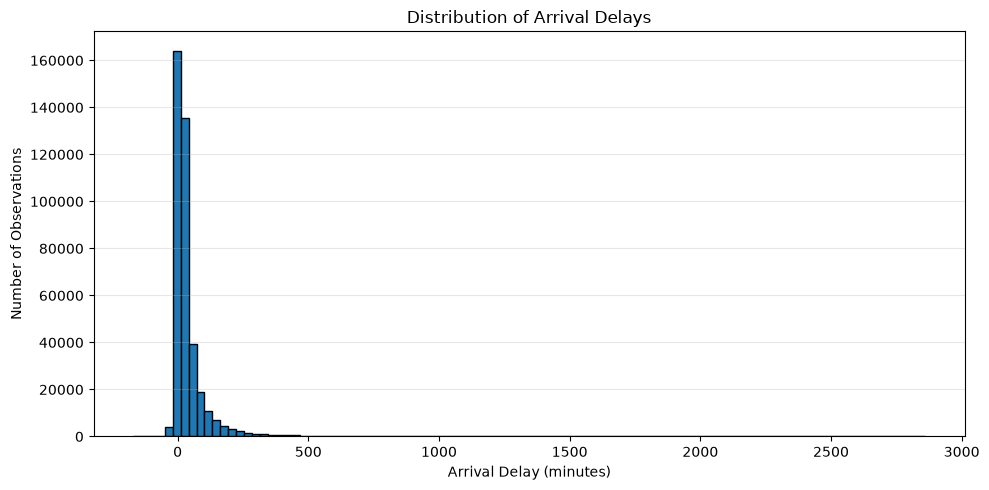

In [122]:
plt.figure(figsize=(10, 5))

plt.hist(
    arrival_delay,
    bins=100,
    edgecolor="black"
)

plt.title("Distribution of Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Observations")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Arrival Delay Distribution: Detailed View

The initial histogram shows the overall arrival-delay distribution. However, very large delays make it difficult to examine the concentration of ordinary delays.

In this step, we will create a focused histogram of arrival delays between −200 and 300 minutes. This is only a visualization range; the original cleaned dataset remains unchanged.

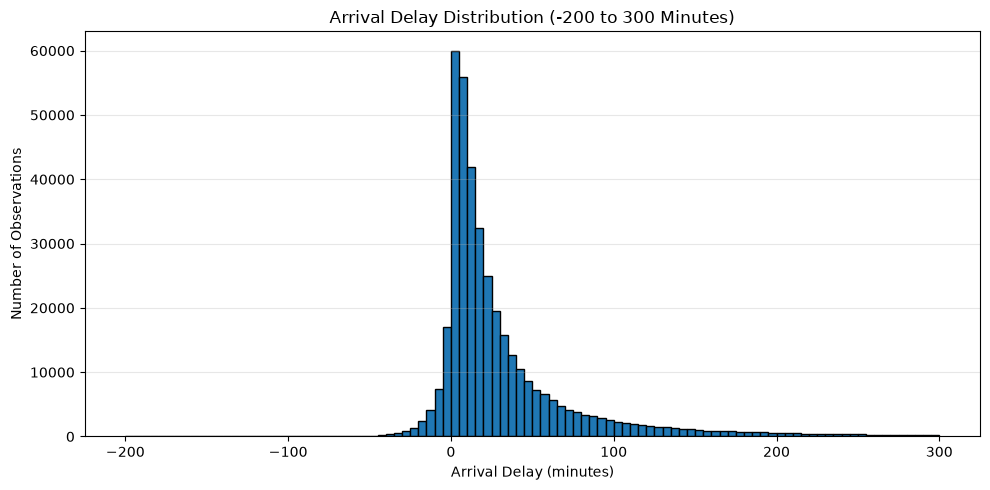

In [124]:
plt.figure(figsize=(10, 5))

plt.hist(
    arrival_delay,
    bins=100,
    range=(-200, 300),
    edgecolor="black"
)

plt.title("Arrival Delay Distribution (-200 to 300 Minutes)")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Observations")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Arrival Delay Analysis by Train Category

In this step, we will analyze arrival delays across different train categories.

We will calculate the number of observations, average delay, median delay, and maximum delay for each category. This analysis will help us understand whether arrival-delay patterns differ between train categories.

In [28]:
# Group arrival delays by train category
category_delay_summary = (
    model_df_clean
    .groupby("category")["arrival_delay_min"]
    .agg(
        observations="count",
        average_delay="mean",
        median_delay="median",
        maximum_delay="max"
    )
    .sort_values(by="average_delay", ascending=False)
)

# Display the summary
category_delay_summary

,observations,average_delay,median_delay,maximum_delay
category,,,,
PEXP,64,315.140625,151.0,2442.0
TOD,9747,174.291987,82.0,1805.0
AMTB,1864,80.226395,29.5,613.0
DRNT,432,73.009259,14.0,1219.0
EMU,2624,53.983613,35.0,359.0
SUF,48412,46.550050,19.0,1028.0
MEMU,58188,43.426359,23.0,2754.0
GBR,1004,41.566733,18.0,328.0
MEX,127120,39.370312,20.0,1183.0


## Arrival Delay vs. Train Station Sequence

A train passes through multiple stations during a run. Its arrival delay may change as it progresses along the route.

In this step, we will examine the relationship between station sequence and arrival delay. We will calculate the number of observations, median delay, and average delay at each sequence position.

This analysis will help us understand whether delays tend to accumulate or reduce as trains progress through their routes.

In [36]:
# Group arrival delays by station sequence
sequence_delay_summary = (
    model_df_clean
    .groupby("seq")["arrival_delay_min"]
    .agg(
        observations="count",
        median_delay="median",
        average_delay="mean"
    )
    .sort_index()
)

# Display the first 20 sequence positions
sequence_delay_summary.head(20)


,observations,median_delay,average_delay
seq,,,
2,19564,6.0,17.794163
3,22271,7.0,19.216964
4,21728,10.0,22.202780
5,20436,12.0,26.030730
6,19371,13.0,27.823499
7,19451,13.0,29.410827
8,18687,14.0,31.157275
9,18030,15.0,32.962174
10,17032,16.0,34.293800


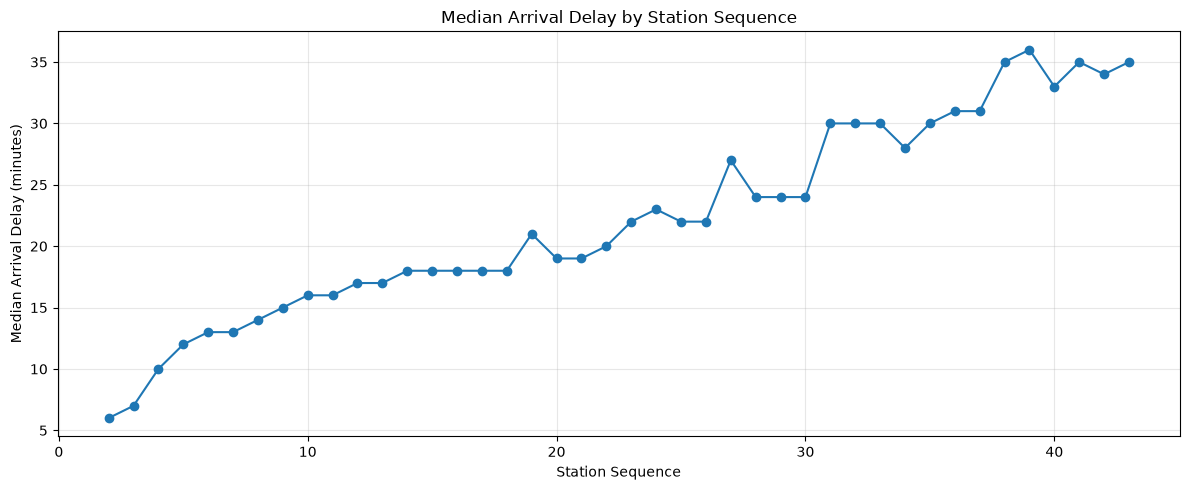

In [31]:
# Keep sequence positions with at least 1000 observations
sequence_plot_data = sequence_delay_summary[
    sequence_delay_summary["observations"] >= 1000
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    sequence_plot_data.index,
    sequence_plot_data["median_delay"],
    marker="o"
)

plt.title("Median Arrival Delay by Station Sequence")
plt.xlabel("Station Sequence")
plt.ylabel("Median Arrival Delay (minutes)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Arrival Delay by Scheduled Arrival Hour (IST)

Train delays may vary depending on the time of day. In this step, we will examine whether trains scheduled to arrive during different hours experience different arrival delays.

The scheduled arrival timestamps are stored in UTC. Since the trains operate in India, we will convert these timestamps to Indian Standard Time (IST) before extracting the scheduled arrival hour.

We will calculate the number of observations, average delay, and median delay for each hour. This analysis may help us identify whether scheduled arrival time is a useful feature for predicting train delays.

In [41]:
# Convert scheduled arrival timestamps from UTC to IST
model_df_clean["scheduled_arrival_ist"] = (
    model_df_clean["scheduled_arrival"]
    .dt.tz_convert("Asia/Kolkata")
)

# Extract scheduled arrival hour in IST
model_df_clean["scheduled_arrival_hour"] = (
    model_df_clean["scheduled_arrival_ist"].dt.hour
)

# Verify the conversion
model_df_clean[
    [
        "scheduled_arrival",
        "scheduled_arrival_ist",
        "scheduled_arrival_hour"
    ]
].head()

,scheduled_arrival,scheduled_arrival_ist,scheduled_arrival_hour
0,2026-10-06 21:50:00+00:00,2026-10-07 03:20:00+05:30,3
1,2026-10-07 13:30:00+00:00,2026-10-07 19:00:00+05:30,19
2,2026-10-07 23:20:00+00:00,2026-10-08 04:50:00+05:30,4
3,2026-10-08 10:35:00+00:00,2026-10-08 16:05:00+05:30,16
4,2026-10-08 22:35:00+00:00,2026-10-09 04:05:00+05:30,4


In [42]:
# Group arrival delays by scheduled arrival hour in IST
hourly_delay_summary = (
    model_df_clean
    .groupby("scheduled_arrival_hour")["arrival_delay_min"]
    .agg(
        observations="count",
        average_delay="mean",
        median_delay="median"
    )
    .sort_index()
)

# Display the summary
hourly_delay_summary

,observations,average_delay,median_delay
scheduled_arrival_hour,,,
0,9150,47.377596,20.0
1,7543,50.341774,22.0
2,7481,53.073252,23.0
3,8273,48.847576,20.0
4,11240,40.730961,14.0
5,16083,32.957844,12.0
6,20363,30.757108,12.0
7,23921,30.145103,13.0
8,23866,31.206570,14.0


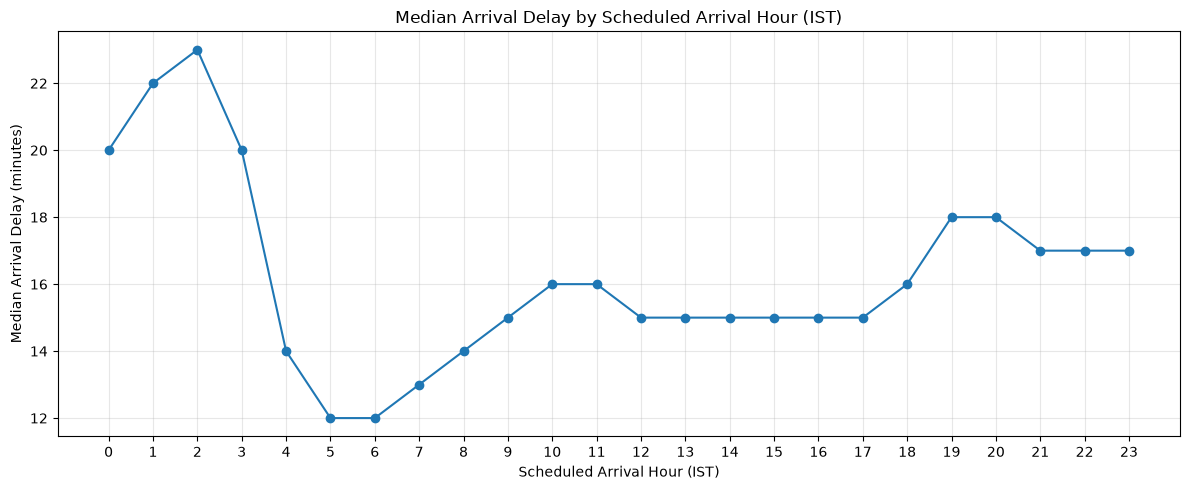

In [123]:
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_delay_summary.index,
    hourly_delay_summary["median_delay"],
    marker="o"
)

plt.title("Median Arrival Delay by Scheduled Arrival Hour (IST)")
plt.xlabel("Scheduled Arrival Hour (IST)")
plt.ylabel("Median Arrival Delay (minutes)")

plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Delay Progression Between Consecutive Stations

A train's arrival delay may change as it travels from one station to the next. It may gain additional delay or recover some of its existing delay.

In this step, we will calculate the change in arrival delay between consecutive stations within the same train run.

A positive delay change indicates that the train became more delayed, while a negative delay change indicates that it recovered some delay.

This analysis will help us understand how arrival delays evolve along individual train routes.

In [48]:
# Sort records by train run and station sequence
delay_progression_df = model_df_clean.sort_values(
    by=["train_number", "start_date", "seq"]
).copy()

# Reset the index
delay_progression_df = delay_progression_df.reset_index(drop=True)

# Display a few records
delay_progression_df[
    [
        "train_number",
        "start_date",
        "seq",
        "station_code",
        "arrival_delay_min"
    ]
].head(10)


,train_number,start_date,seq,station_code,arrival_delay_min
0,00461,2026-10-18,2,UMB,43.0
1,00461,2026-10-18,3,BBMN,70.0
2,00461,2026-10-18,4,SVDK,428.0
3,00461,2026-10-18,5,BDGM,95.0
4,00461,2026-10-22,2,UMB,45.0
5,00461,2026-10-22,3,BBMN,240.0
6,00461,2026-10-22,4,SVDK,610.0
7,00461,2026-10-22,5,BDGM,325.0
8,00461,2026-11-03,2,UMB,-16.0
9,00461,2026-11-03,3,BBMN,65.0


In [49]:
# Get the previous station's arrival delay within the same train run
delay_progression_df["previous_arrival_delay"] = (
    delay_progression_df
    .groupby(["train_number", "start_date"])["arrival_delay_min"]
    .shift(1)
)

# Calculate the change in arrival delay
delay_progression_df["delay_change_min"] = (
    delay_progression_df["arrival_delay_min"]
    - delay_progression_df["previous_arrival_delay"]
)

# Display the result
delay_progression_df[
    [
        "train_number",
        "start_date",
        "seq",
        "station_code",
        "previous_arrival_delay",
        "arrival_delay_min",
        "delay_change_min"
    ]
].head(15)

,train_number,start_date,seq,station_code,previous_arrival_delay,arrival_delay_min,delay_change_min
0,00461,2026-10-18,2,UMB,NaN,43.0,NaN
1,00461,2026-10-18,3,BBMN,43.0,70.0,27.0
2,00461,2026-10-18,4,SVDK,70.0,428.0,358.0
3,00461,2026-10-18,5,BDGM,428.0,95.0,-333.0
4,00461,2026-10-22,2,UMB,NaN,45.0,NaN
5,00461,2026-10-22,3,BBMN,45.0,240.0,195.0
6,00461,2026-10-22,4,SVDK,240.0,610.0,370.0
7,00461,2026-10-22,5,BDGM,610.0,325.0,-285.0
8,00461,2026-11-03,2,UMB,NaN,-16.0,NaN
9,00461,2026-11-03,3,BBMN,-16.0,65.0,81.0


In [51]:
# Calculate overall delay progression statistics
delay_change_summary = (
    delay_progression_df["delay_change_min"]
    .dropna()
    .describe()
)

delay_change_summary.round(2)


count    366454.00
mean          0.54
std          20.22
min        -531.00
25%          -3.00
50%           1.00
75%           4.00
max        2863.00
Name: delay_change_min, dtype: float64

### Delay Change Across Station Sequence

In this analysis, we examine how arrival delay changes at different station sequence positions. This helps us understand whether trains tend to recover delay or become more delayed as they progress through their journeys.

The median is used because it is less affected by unusually large delay changes than the mean.

In [53]:
delay_change_by_sequence = (
    delay_progression_df
    .groupby("seq")["delay_change_min"]
    .agg(
        observations="count",
        median_change="median",
        average_change="mean"
    )
    .sort_index()
)

delay_change_by_sequence.head()

,observations,median_change,average_change
seq,,,
2,0,NaN,NaN
3,15724,2.0,3.951730
4,18987,1.0,3.016538
5,19184,1.0,2.791076
6,18929,1.0,2.296582


### Station-wise Arrival Delay

In this analysis, we examine arrival delays at different stations using the station code.

The median arrival delay is calculated for each station to understand its typical delay. The number of observations is also considered because stations with very few records may produce unreliable comparisons.

Only stations with at least 500 observations are included in the visualization. This threshold is used for analysis and does not remove records from the dataset.

In [57]:
station_delay_summary = (
    model_df_clean
    .groupby("station_code")["arrival_delay_min"]
    .agg(
        observations="count",
        median_delay="median",
        average_delay="mean"
    )
    .sort_values("median_delay", ascending=False)
)

station_delay_summary.head(10)

,observations,median_delay,average_delay
station_code,,,
GNJP,1,1513.0,1513.000000
NJAJ,3,515.0,410.333333
DTV,4,343.0,309.000000
SCMN,5,325.0,315.600000
PNPL,4,323.5,303.000000
BRBS,5,272.0,276.400000
MJHL,1,267.0,267.000000
PHX,1,266.0,266.000000
BHKL,1,265.0,265.000000


In [58]:
station_plot_data = station_delay_summary[
    station_delay_summary["observations"] >= 500
]

print("Total stations:", len(station_delay_summary))
print("Stations with at least 500 observations:", len(station_plot_data))

Total stations: 6479
Stations with at least 500 observations: 66


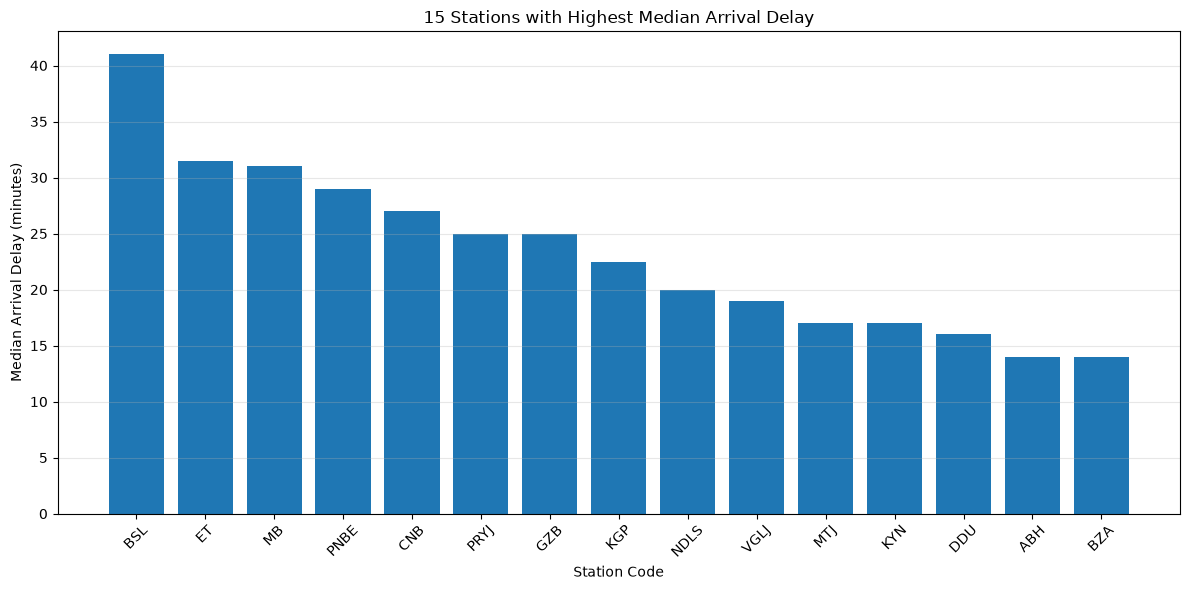

In [59]:
top_delay_stations = station_plot_data.head(15)

plt.figure(figsize=(12, 6))

plt.bar(
    top_delay_stations.index,
    top_delay_stations["median_delay"]
)

plt.title("15 Stations with Highest Median Arrival Delay")
plt.xlabel("Station Code")
plt.ylabel("Median Arrival Delay (minutes)")
plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Exploratory Data Analysis — Conclusion

Exploratory Data Analysis was performed to understand the railway dataset and identify important patterns in train arrival delays.

The analysis showed that arrival delays are right-skewed, with most observations having relatively small delays and a smaller number of trains experiencing very large delays. The median arrival delay was lower than the mean, indicating the influence of extreme positive delays.

Arrival delays were found to vary across train categories. Some categories showed higher average and median delays, while others generally experienced lower delays. Categories with very few observations were interpreted carefully.

The analysis of scheduled arrival time in Indian Standard Time (IST) showed variations in median delay across different hours. The station-wise analysis also indicated that typical arrival delays differ across stations.

Delay changes between consecutive stations were generally small for most observations, although some train runs experienced larger increases or recoveries. The station-sequence analysis showed that delay patterns can vary across different stages of a train's journey.

During data preparation, duplicate records and data-quality issues were examined. The dataset was prepared for modeling by selecting completed train runs, excluding origin-station records from arrival-delay modeling, and correcting suspected scheduled-arrival date inconsistencies based on station-sequence evidence.

Overall, EDA provided a better understanding of the target variable, its distribution, and the factors that may be useful for prediction. The cleaned dataset is now ready for feature selection, feature engineering, and regression model development.

# Machine Learning Preparation

## Prediction Objective

The objective of BookWisely is to predict the arrival delay of a train at a particular station.

The target variable is `arrival_delay_min`, which represents the arrival delay in minutes.

Since the target is a continuous numerical value, this project is a regression problem.

The model will use information such as train category, station sequence, station code, and scheduled arrival time to estimate the arrival delay.

Only features that are available before the actual arrival should be used for prediction. Actual arrival and departure information will be excluded to prevent data leakage.

In [63]:
target_column = "arrival_delay_min"

print("Target variable:", target_column)
print("Number of observations:", model_df_clean[target_column].count())
print("Mean arrival delay:", model_df_clean[target_column].mean())
print("Median arrival delay:", model_df_clean[target_column].median())
print("Minimum delay:", model_df_clean[target_column].min())
print("Maximum delay:", model_df_clean[target_column].max())

Target variable: arrival_delay_min
Number of observations: 398575
Mean arrival delay: 38.22293922097472
Median arrival delay: 15.0
Minimum delay: -170.0
Maximum delay: 2860.0


## Creating the Feature DataFrame and Target Variable

After selecting the relevant features, we separate the dataset into input features and the target variable.

- **X (Features):** Contains the input columns used by the machine learning model, such as train category, station sequence, station code, and scheduled arrival hour in IST.
- **y (Target):** Contains the `arrival_delay_min` values that the model will learn to predict.

This separation is required for supervised machine learning. The features provide information to the model, while the target represents the expected output.

The original cleaned dataset remains unchanged because we create copies of the selected data.

In [64]:
target_column = "arrival_delay_min"

X = model_df_clean[
    [
        "category",
        "seq",
        "station_code",
        "scheduled_arrival_hour"
    ]
].copy()

y = model_df_clean[target_column].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

X.head()

Feature shape: (398575, 4)
Target shape: (398575,)


,category,seq,station_code,scheduled_arrival_hour
0,PEXP,2,TKD,3
1,PEXP,3,BPL,19
2,PEXP,4,NGP,4
3,PEXP,5,BZA,16
4,PEXP,6,RU,4


## Feature Inspection

Before preparing the dataset for machine learning, we inspect the selected input features and target variable.

This step helps us understand the data types, identify missing values, and verify that the selected columns are suitable for further preprocessing.

The inspection is performed on the feature DataFrame `X` and target variable `y`. The original cleaned dataset is not modified.

In [67]:
# Check the data types and non-null values of features

display(X.info())


<class 'pandas.DataFrame'>
RangeIndex: 398575 entries, 0 to 398574
Data columns (total 4 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   category                398575 non-null  str  
 1   seq                     398575 non-null  int16
 2   station_code            398575 non-null  str  
 3   scheduled_arrival_hour  398575 non-null  int32
dtypes: int16(1), int32(1), str(2)
memory usage: 10.9 MB


None

In [68]:
# Check missing values in input features

display(X.isnull().sum())



category                  0
seq                       0
station_code              0
scheduled_arrival_hour    0
dtype: int64

In [71]:
# Check missing values in target variable

y.isnull().sum()



np.int64(0)

In [70]:
# Display the first five rows of features

display(X.head())

,category,seq,station_code,scheduled_arrival_hour
0,PEXP,2,TKD,3
1,PEXP,3,BPL,19
2,PEXP,4,NGP,4
3,PEXP,5,BZA,16
4,PEXP,6,RU,4


## Feature Preprocessing

The selected features contain both numerical and categorical data.

Numerical features represent measurable values, such as station sequence and scheduled arrival hour. Categorical features represent labels, such as train category and station code.

Machine learning models require numerical input. Therefore, categorical features must be converted into numerical representations before model training.

In this project, categorical encoding will be applied to the train category and station code, while numerical features will be retained in their numerical form.

In [72]:
# Identify numerical and categorical features

numerical_features = [
    "seq",
    "scheduled_arrival_hour"
]

categorical_features = [
    "category",
    "station_code"
]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['seq', 'scheduled_arrival_hour']
Categorical features: ['category', 'station_code']


## Train-Test Split

The dataset is divided into training and testing sets using a chronological split. This ensures that earlier train runs are used for training and later runs are used for testing.

All stations belonging to the same train run are kept in the same set to avoid data leakage.

In [102]:
# Get unique train runs and their dates
run_dates = (
    model_df_clean[["train_number", "start_date"]]
    .drop_duplicates()
    .sort_values("start_date")
)

# Create a unique identifier for each run
run_dates["run_id"] = (
    run_dates["train_number"].astype(str)
    + "_"
    + run_dates["start_date"].astype(str)
)

# Find the date at the 80% position
split_position = int(run_dates["start_date"].nunique() * 0.80)

unique_dates = sorted(run_dates["start_date"].unique())

split_date = unique_dates[split_position]

# Training data: dates before the split date
train_runs = set(
    run_dates.loc[
        run_dates["start_date"] < split_date, "run_id"
    ]
)

# Testing data: split date and all later dates
test_runs = set(
    run_dates.loc[
        run_dates["start_date"] >= split_date, "run_id"
    ]
)

# Create run identifiers for the complete dataset
run_id = (
    model_df_clean["train_number"].astype(str)
    + "_"
    + model_df_clean["start_date"].astype(str)
)

# Divide the dataset
train_mask = run_id.isin(train_runs)
test_mask = run_id.isin(test_runs)

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training runs:", len(train_runs))
print("Testing runs:", len(test_runs))
print("Latest training date:", model_df_clean.loc[train_mask, "start_date"].max())
print("Earliest testing date:", model_df_clean.loc[test_mask, "start_date"].min())

Training observations: 312577
Testing observations: 85998
Training runs: 25062
Testing runs: 7059
Latest training date: 2026-11-10
Earliest testing date: 2026-11-11


### Encoding Categorical Features

Machine learning models generally require numerical input. The features `category` and `station_code` contain categorical values, so they must be converted into numerical representations.

One-Hot Encoding creates a separate binary column for each category. We will use a sparse representation because `station_code` contains many unique values.

The encoder will be fitted only on the training data to prevent data leakage. Unknown categories in the test data will be handled safely.

In [103]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Define categorical and numerical features
categorical_features = ["category", "station_code"]
numerical_features = ["seq", "scheduled_arrival_hour"]

# Create the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

# Fit the encoder using training data only
X_train_encoded = preprocessor.fit_transform(X_train)

# Transform the testing data using the same encoder
X_test_encoded = preprocessor.transform(X_test)

print("Training data shape after encoding:", X_train_encoded.shape)
print("Testing data shape after encoding:", X_test_encoded.shape)

Training data shape after encoding: (312577, 6477)
Testing data shape after encoding: (85998, 6477)


### Building a Baseline Regression Model

A baseline model provides a simple reference point for evaluating machine learning models.

We will use `DummyRegressor` with the median strategy. It predicts the median arrival delay from the training data for every observation.

This model does not learn relationships between features and delays. Its purpose is to establish a performance benchmark for comparison with more advanced models.

In [121]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create and train the baseline model
dummy_model = DummyRegressor(strategy="median")

dummy_model.fit(X_train_encoded, y_train)

# Make predictions
dummy_predictions = dummy_model.predict(X_test_encoded)

# Evaluate the baseline model
dummy_mae = mean_absolute_error(y_test, dummy_predictions)
dummy_rmse = np.sqrt(mean_squared_error(y_test, dummy_predictions))
dummy_r2 = r2_score(y_test, dummy_predictions)

print("Dummy Baseline Model")
print("-------------------")
print("MAE:", round(dummy_mae, 2))
print("RMSE:", round(dummy_rmse, 2))
print("R² Score:", round(dummy_r2, 4))

Dummy Baseline Model
-------------------
MAE: 33.06
RMSE: 76.34
R² Score: -0.0943


### Model 1: Linear Regression

Linear Regression is a supervised machine learning algorithm used to predict continuous numerical values.

It learns a relationship between input features and the target variable by minimizing the prediction errors on the training data.

In this project, Linear Regression will predict the arrival delay of a train at a station using the selected features.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create and train the Linear Regression model
linear_model = LinearRegression()

linear_model.fit(X_train_encoded, y_train)

# Make predictions
linear_predictions = linear_model.predict(X_test_encoded)

# Evaluate the model
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression")
print("----------------")
print("MAE:", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))
print("R² Score:", round(linear_r2, 4))

Linear Regression
----------------
MAE: 31.67
RMSE: 63.19
R² Score: 0.2503


### Model 2: Random Forest Regressor

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees.

Each tree learns patterns from the training data, and the final regression prediction is calculated by averaging the predictions of the individual trees.

Random Forest can capture nonlinear relationships between train categories, stations, sequence positions, scheduled arrival hours, and arrival delays.

In [127]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Create and train the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_encoded, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test_encoded)

# Evaluate the model
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Regressor")
print("-----------------------")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R² Score:", round(rf_r2, 4))

Random Forest Regressor
-----------------------
MAE: 37.85
RMSE: 70.86
R² Score: 0.0573


### Model 3: HistGradientBoosting Regressor

HistGradientBoosting is an ensemble learning algorithm that builds decision trees sequentially to improve prediction performance.

Each new tree attempts to reduce the errors made by the previous trees. The predictions from these trees are combined to produce the final regression output.

For this model, Ordinal Encoding is used to convert categorical features into numerical values. This approach provides a memory-conscious representation for features containing many unique categories.

The model is configured with 100 boosting iterations, a maximum of 31 leaf nodes per tree, and a learning rate of 0.1.

The model is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

In [126]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create preprocessing for categorical features
hist_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ),
            categorical_features
        )
    ],
    remainder="passthrough"
)

# Create the HistGradientBoosting model pipeline
hist_model = Pipeline(
    steps=[
        ("preprocessor", hist_preprocessor),
        (
            "regressor",
            HistGradientBoostingRegressor(
                max_iter=100,
                max_leaf_nodes=31,
                learning_rate=0.1,
                random_state=42
            )
        )
    ]
)

# Train the model using the original training features
hist_model.fit(X_train, y_train)

# Make predictions
hist_predictions = hist_model.predict(X_test)

# Evaluate the model
hist_mae = mean_absolute_error(y_test, hist_predictions)
hist_rmse = np.sqrt(mean_squared_error(y_test, hist_predictions))
hist_r2 = r2_score(y_test, hist_predictions)

print("HistGradientBoosting Regressor")
print("------------------------------")
print("MAE:", round(hist_mae, 2))
print("RMSE:", round(hist_rmse, 2))
print("R² Score:", round(hist_r2, 4))

HistGradientBoosting Regressor
------------------------------
MAE: 33.24
RMSE: 64.51
R² Score: 0.2185


### Model Comparison

After training three regression models, we compare their performance using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

MAE and RMSE measure prediction errors in minutes, while R² measures how well the model explains variation in arrival delays.

The model with lower MAE and RMSE and a higher R² is generally preferred.

In [108]:
# Create a comparison of all models
model_comparison = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "Linear Regression",
        "Random Forest",
        "HistGradientBoosting"
    ],
    "MAE": [
        dummy_mae,
        linear_mae,
        rf_mae,
        hist_mae
    ],
    "RMSE": [
        dummy_rmse,
        linear_rmse,
        rf_rmse,
        hist_rmse
    ],
    "R² Score": [
        dummy_r2,
        linear_r2,
        rf_r2,
        hist_r2
    ]
})

# Sort models by MAE (lower is better)
model_comparison = model_comparison.sort_values(
    by="MAE"
).reset_index(drop=True)

# Display comparison
model_comparison.round(4)

,Model,MAE,RMSE,R² Score
0,Linear Regression,31.6731,63.1887,0.2503
1,Dummy Baseline,33.0642,76.3416,-0.0943
2,HistGradientBoosting,33.2424,64.5148,0.2185
3,Random Forest,37.8459,70.8580,0.0573


## Prediction Accuracy Within a Time Tolerance

This evaluation measures how often the predicted arrival delay is close to the actual arrival delay.

A prediction is considered within tolerance when the absolute difference between the actual and predicted delay is less than or equal to a specified number of minutes.

We will calculate the percentage of predictions falling within ±5, ±10, ±15, ±30, and ±60 minutes for each model.

In [114]:
# Calculate prediction performance within different time tolerances

actual = y_test.to_numpy()

# Predictions from all evaluated models
model_predictions = {
    "Linear Regression": linear_predictions,
    "Random Forest": rf_predictions,
    "HistGradientBoosting": hist_predictions,
    "Dummy Baseline": dummy_predictions
}

# Define time tolerances in minutes
tolerances = [5, 10, 15, 30, 60]

accuracy_results = []

for model_name, predictions in model_predictions.items():

    # Calculate absolute prediction errors
    absolute_errors = np.abs(actual - predictions)

    result = {"Model": model_name}

    # Calculate percentage within each tolerance
    for tolerance in tolerances:

        percentage = (
            np.mean(absolute_errors <= tolerance) * 100
        )

        result[f"Within ±{tolerance} min"] = round(
            percentage, 2
        )

    accuracy_results.append(result)

# Create and display the results table
accuracy_table = pd.DataFrame(accuracy_results)

accuracy_table

,Model,Within ±5 min,Within ±10 min,Within ±15 min,Within ±30 min,Within ±60 min
0,Linear Regression,18.58,34.48,46.68,68.81,87.26
1,Random Forest,6.41,13.29,21.20,58.84,89.98
2,HistGradientBoosting,15.61,30.67,41.93,67.14,87.43
3,Dummy Baseline,20.34,40.43,59.86,76.14,87.01


### Interpretation of Prediction Accuracy

The tolerance-based evaluation provides additional insight into the prediction performance of the models.

- Dummy Baseline achieved the highest percentage of predictions within ±5, ±10, ±15, and ±30 minutes.
- Random Forest achieved the highest percentage within ±60 minutes.
- Linear Regression achieved the lowest MAE and RMSE among the evaluated models, although it did not lead in the stricter tolerance-based measurements.

These results show that model performance depends on the acceptable prediction error. A lower average error does not necessarily mean that more individual predictions fall within every specified tolerance.

Therefore, Linear Regression remains the best model according to the overall MAE, RMSE, and R² evaluation, but its practical prediction performance should be considered alongside the tolerance-based results.

### Prediction Analysis of the Best Model

Linear Regression achieved the best performance among the three evaluated models.

We will visualize its predictions to understand how closely they match actual arrival delays. We will also examine the residuals, which represent the difference between actual and predicted values.

These visualizations help identify prediction patterns and possible errors that are not fully captured by evaluation metrics.

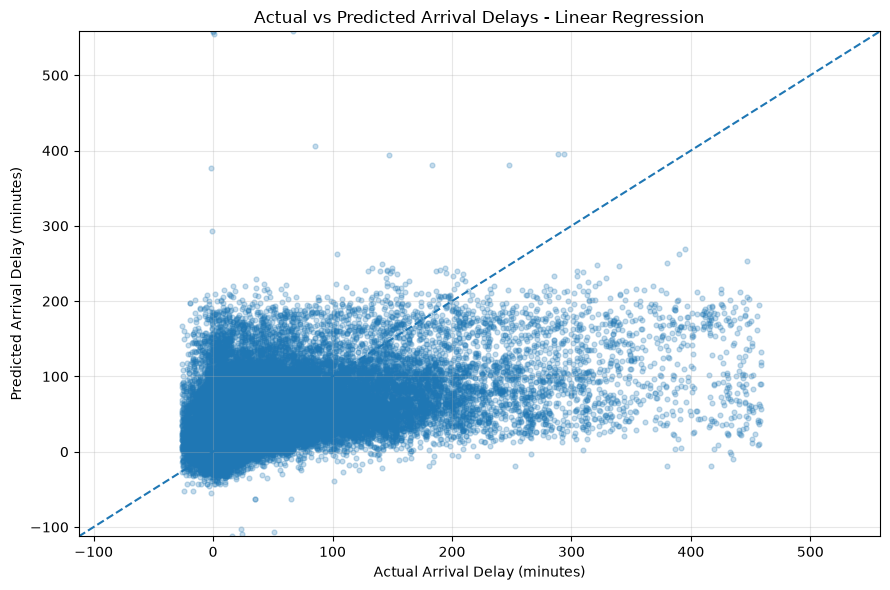

In [116]:
# Actual and predicted values from the best model
actual = y_test.to_numpy()
predicted = linear_predictions

# Keep the central 99% of actual values for visualization
lower_limit = np.percentile(actual, 0.5)
upper_limit = np.percentile(actual, 99.5)

visible = (
    (actual >= lower_limit) &
    (actual <= upper_limit)
)

plot_actual = actual[visible]
plot_predicted = predicted[visible]

# Determine plot boundaries
plot_min = min(plot_actual.min(), plot_predicted.min())
plot_max = max(plot_actual.max(), plot_predicted.max())

# Plot actual vs predicted values
plt.figure(figsize=(9, 6))

plt.scatter(
    plot_actual,
    plot_predicted,
    alpha=0.25,
    s=12
)

# Perfect prediction reference line
plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--"
)

plt.title("Actual vs Predicted Arrival Delays - Linear Regression")
plt.xlabel("Actual Arrival Delay (minutes)")
plt.ylabel("Predicted Arrival Delay (minutes)")

plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Focused Prediction and Residual Analysis

The prediction graph contains extreme delay values that make the central observations difficult to examine.

We will create focused visualizations using the 99th percentile of actual delays and residuals. These plots will help us understand the model's behavior for most observations while keeping the complete test dataset unchanged.

In [111]:
# Calculate residuals
residuals = y_test.to_numpy() - linear_predictions

# Keep the central 99% of residuals for visualization
lower_limit = np.percentile(residuals, 0.5)
upper_limit = np.percentile(residuals, 99.5)

visible = (
    (residuals >= lower_limit) &
    (residuals <= upper_limit)
)

visible_residuals = residuals[visible]
visible_predictions = linear_predictions[visible]



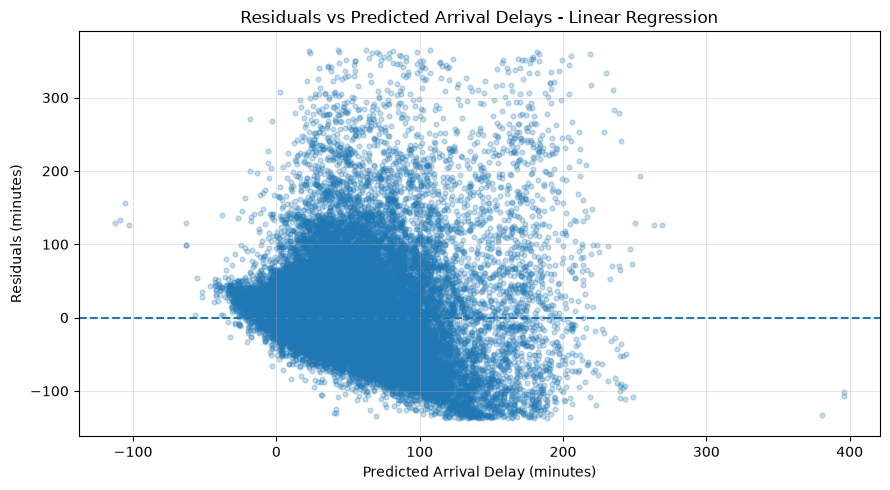

In [112]:
# Residuals vs Predicted Values
plt.figure(figsize=(9, 5))

plt.scatter(
    visible_predictions,
    visible_residuals,
    alpha=0.25,
    s=12
)

plt.axhline(y=0, linestyle="--")

plt.title("Residuals vs Predicted Arrival Delays - Linear Regression")
plt.xlabel("Predicted Arrival Delay (minutes)")
plt.ylabel("Residuals (minutes)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



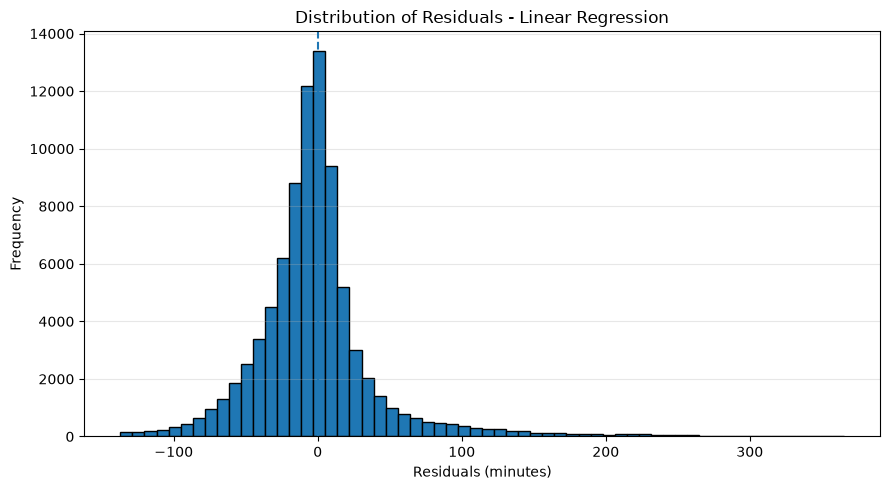

In [113]:
# Distribution of Residuals
plt.figure(figsize=(9, 5))

plt.hist(
    visible_residuals,
    bins=60,
    edgecolor="black"
)

plt.axvline(x=0, linestyle="--")

plt.title("Distribution of Residuals - Linear Regression")
plt.xlabel("Residuals (minutes)")
plt.ylabel("Frequency")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Final Model Evaluation and Conclusion

## 1. Project Objective

The objective of BookWisely is to predict train arrival delays in minutes using machine learning regression models.

The target variable used for prediction is `arrival_delay_min`.

The models were evaluated using a chronological train-test split to assess their ability to predict delays for later train runs.

## 2. Model Performance Comparison

Four models were evaluated: one Dummy Baseline model and three regression models.

| Model | MAE | RMSE | R² Score |
|---|---:|---:|---:|
| Dummy Baseline | 33.06 | 76.34 | -0.0943 |
| Linear Regression | 31.67 | 63.19 | 0.2503 |
| Random Forest | 37.85 | 70.86 | 0.0573 |
| HistGradientBoosting | 33.24 | 64.51 | 0.2185 |

Linear Regression achieved the lowest MAE and RMSE and the highest R² score among the three regression models.

Its MAE of 31.67 minutes indicates that its predictions differ from actual arrival delays by an average absolute amount of approximately 32 minutes.

Its R² score of 0.2503 indicates that the model explains approximately 25.03% of the variation in the test-set arrival delays.

## 3. Prediction Performance Within Time Tolerances

The percentage-based evaluation measured how many predictions were within specified time differences from the actual arrival delays.

| Model | ±5 min | ±10 min | ±15 min | ±30 min | ±60 min |
|---|---:|---:|---:|---:|---:|
| Linear Regression | 18.58% | 34.48% | 46.68% | 68.81% | 87.26% |
| Random Forest | 6.41% | 13.29% | 21.20% | 58.84% | 89.98% |
| HistGradientBoosting | 15.61% | 30.67% | 41.93% | 67.14% | 87.43% |
| Dummy Baseline | 20.34% | 40.43% | 59.86% | 76.14% | 87.01% |

The Dummy Baseline achieved the highest percentage of predictions within ±5, ±10, ±15, and ±30 minutes. Random Forest achieved the highest percentage within ±60 minutes.

These results demonstrate that the model with the lowest average error does not necessarily produce the highest percentage of predictions within every time tolerance.

## 4. Residual Analysis

The Actual vs Predicted graph showed that Linear Regression captures some of the arrival-delay patterns but tends to underestimate certain large delays.

The residual plots revealed a positively skewed error distribution and increasing error variation at higher predicted delays.

These observations indicate that the model does not perform equally well across all delay ranges.

## 5. Final Conclusion

Among the three regression models, Linear Regression achieved the strongest performance according to the conventional regression metrics MAE, RMSE, and R².

However, the tolerance-based evaluation showed that the Dummy Baseline performed better for stricter prediction tolerances, while Random Forest performed better within the ±60-minute tolerance.

Therefore, Linear Regression is selected as the best-performing regression model based on the primary evaluation metrics, but its practical prediction limitations must also be considered.

The results indicate that train arrival delays are influenced by patterns that are not fully captured by the selected features.

Future improvements could include additional relevant features, better categorical feature representations, historical train-delay information, and further model optimization.

## Saving the Best Performing Model

Linear Regression achieved the best overall performance among the three regression models based on MAE, RMSE, and R² Score.

The trained model and its fitted preprocessing encoder are saved together using Joblib. This allows the model to be loaded and reused for future predictions without retraining.

In [128]:
import joblib

# Create the Models directory if it does not exist
models_dir = project_dir / "Models"
models_dir.mkdir(parents=True, exist_ok=True)

# Store the trained model and preprocessing encoder together
model_bundle = {
    "model": linear_model,
    "preprocessor": preprocessor,
    "feature_columns": list(X.columns),
    "target_column": "arrival_delay_min",
    "model_name": "Linear Regression"
}

# Define the model file path
model_path = models_dir / "bookwisely_linear_regression.joblib"

# Save the model bundle
joblib.dump(model_bundle, model_path)

print("Model saved successfully!")
print("Model location:", model_path)
print("File size:", round(model_path.stat().st_size / (1024 * 1024), 2), "MB")

Model saved successfully!
Model location: c:\Users\bhaga\OneDrive\Documents\Study Materials\spyder_py\MLProject\Models\bookwisely_linear_regression.joblib
File size: 0.09 MB


## Loading and Testing the Saved Model

The saved Linear Regression model is loaded using Joblib.

The fitted preprocessing encoder is also loaded to transform new input data into the numerical format expected by the model.

A test observation is used to verify that the saved model can successfully generate an arrival-delay prediction without retraining.

In [129]:
# Load the saved model bundle
loaded_bundle = joblib.load(model_path)

# Retrieve the trained model and preprocessing encoder
loaded_model = loaded_bundle["model"]
loaded_preprocessor = loaded_bundle["preprocessor"]
feature_columns = loaded_bundle["feature_columns"]

print("Saved model loaded successfully!")
print("Model:", loaded_bundle["model_name"])

# Select one observation from the test dataset
sample_input = X_test[feature_columns].iloc[[0]].copy()

# Get the actual arrival delay
actual_delay = y_test.iloc[0]

# Transform the input using the saved encoder
sample_encoded = loaded_preprocessor.transform(sample_input)

# Generate prediction
predicted_delay = loaded_model.predict(sample_encoded)[0]

# Calculate prediction error
absolute_error = abs(actual_delay - predicted_delay)

# Display results
print("\nPrediction Test")
print("----------------")
print("Input details:")
display(sample_input)

print("Actual arrival delay:", round(actual_delay, 2), "minutes")
print("Predicted arrival delay:", round(predicted_delay, 2), "minutes")
print("Absolute prediction error:", round(absolute_error, 2), "minutes")

Saved model loaded successfully!
Model: Linear Regression

Prediction Test
----------------
Input details:


,category,seq,station_code,scheduled_arrival_hour
307992,PAS,3,SGA,19


Actual arrival delay: 6.0 minutes
Predicted arrival delay: 14.53 minutes
Absolute prediction error: 8.53 minutes


## Creating a Reusable Prediction Function

A reusable prediction function allows users to provide train details and receive an estimated arrival delay.

The function uses the saved preprocessing encoder to transform the input features and the trained Linear Regression model to generate the prediction.

The function accepts train category, station sequence, station code, and scheduled arrival hour as input.

In [130]:
def predict_arrival_delay(category, seq, station_code, scheduled_arrival_hour):

    # Validate input values
    if not str(category).strip():
        raise ValueError("Train category cannot be empty.")

    if not str(station_code).strip():
        raise ValueError("Station code cannot be empty.")

    seq = int(seq)
    scheduled_arrival_hour = int(scheduled_arrival_hour)

    if seq < 1:
        raise ValueError("Station sequence must be at least 1.")

    if not 0 <= scheduled_arrival_hour <= 23:
        raise ValueError("Scheduled arrival hour must be between 0 and 23.")

    # Prepare input data
    input_data = pd.DataFrame([{
        "category": str(category).strip().upper(),
        "seq": seq,
        "station_code": str(station_code).strip().upper(),
        "scheduled_arrival_hour": scheduled_arrival_hour
    }], columns=feature_columns)

    # Apply saved preprocessing
    encoded_input = loaded_preprocessor.transform(input_data)

    # Generate prediction
    prediction = loaded_model.predict(encoded_input)[0]

    return prediction


print("Prediction function created successfully!")

Prediction function created successfully!


In [131]:
# Test the reusable prediction function

predicted_delay = predict_arrival_delay(
    category="PAS",
    seq=3,
    station_code="SGA",
    scheduled_arrival_hour=19
)

print("BookWisely Arrival Delay Prediction")
print("-----------------------------------")
print("Train Category: PAS")
print("Station Sequence: 3")
print("Station Code: SGA")
print("Scheduled Arrival Hour: 19")
print("Predicted Arrival Delay:", round(predicted_delay, 2), "minutes")

BookWisely Arrival Delay Prediction
-----------------------------------
Train Category: PAS
Station Sequence: 3
Station Code: SGA
Scheduled Arrival Hour: 19
Predicted Arrival Delay: 14.53 minutes


## Preparing Route Data and Saving All Models

The route data is prepared from the original sampled dataset to identify train services connecting different source and destination stations.

The destination station's sequence number and scheduled arrival hour will be used as input features for delay prediction.

All three trained regression models and the fitted preprocessing components are saved together for use in the BookWisely application.

In [133]:

# Import required library
import joblib
import pandas as pd

# -----------------------------------------------
# 1. Prepare route-stop data from the original df
# -----------------------------------------------

route_columns = [
    "train_number",
    "train_name",
    "category",
    "start_date",
    "status",
    "seq",
    "station_code",
    "scheduled_arrival",
    "scheduled_departure"
]

route_stops = df.loc[
    df["status"].astype(str).str.lower().eq("completed"),
    route_columns
].copy()

# Standardize text fields
route_stops["train_number"] = (
    route_stops["train_number"].astype("string").str.strip()
)

route_stops["category"] = (
    route_stops["category"].astype("string").str.strip().str.upper()
)

route_stops["station_code"] = (
    route_stops["station_code"].astype("string").str.strip().str.upper()
)

# Standardize dates and sequence numbers
route_stops["start_date"] = pd.to_datetime(
    route_stops["start_date"],
    errors="coerce"
).dt.strftime("%Y-%m-%d")

route_stops["seq"] = pd.to_numeric(
    route_stops["seq"],
    errors="coerce"
)

# Convert scheduled times to Indian Standard Time
arrival_ist = pd.to_datetime(
    route_stops["scheduled_arrival"],
    errors="coerce",
    utc=True
).dt.tz_convert("Asia/Kolkata")

departure_ist = pd.to_datetime(
    route_stops["scheduled_departure"],
    errors="coerce",
    utc=True
).dt.tz_convert("Asia/Kolkata")

# Extract destination arrival hour for model prediction
route_stops["scheduled_arrival_hour"] = arrival_ist.dt.hour

# Retain readable scheduled times for the application
route_stops["scheduled_arrival_time"] = arrival_ist.dt.strftime("%H:%M")
route_stops["scheduled_departure_time"] = departure_ist.dt.strftime("%H:%M")

# Keep the required route information
route_stops = route_stops[
    [
        "train_number",
        "train_name",
        "category",
        "start_date",
        "seq",
        "station_code",
        "scheduled_arrival_hour",
        "scheduled_arrival_time",
        "scheduled_departure_time"
    ]
].copy()

# Remove invalid route identifiers
route_stops = route_stops.dropna(
    subset=[
        "train_number",
        "category",
        "start_date",
        "seq",
        "station_code"
    ]
)

route_stops["seq"] = route_stops["seq"].astype(int)

# Remove duplicate stop records
route_stops = route_stops.drop_duplicates(
    subset=["train_number", "start_date", "seq", "station_code"]
)

# Sort route stops
route_stops = route_stops.sort_values(
    ["train_number", "start_date", "seq"]
).reset_index(drop=True)


# -----------------------------------------------
# 2. Save route-stop lookup file
# -----------------------------------------------

processed_dir = project_dir / "Data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

route_file = processed_dir / "route_stops.parquet"

route_stops.to_parquet(
    route_file,
    index=False
)

print("Route data saved successfully!")
print("Route-stop records:", len(route_stops))
print("Distinct station codes:", route_stops["station_code"].nunique())
print("Distinct categories:", route_stops["category"].nunique())
print("Route file:", route_file)


# -----------------------------------------------
# 3. Save all three trained models together
# -----------------------------------------------

models_dir = project_dir / "Models"
models_dir.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "models": {
        "Linear Regression": linear_model,
        "Random Forest": rf_model,
        "HistGradientBoosting": hist_model
    },
    "preprocessor": preprocessor,
    "feature_columns": list(X.columns),
    "target_column": "arrival_delay_min"
}

model_path = models_dir / "bookwisely_all_models.joblib"

joblib.dump(model_bundle, model_path)

print("\nAll three models saved successfully!")
print("Model file:", model_path)
print(
    "Model file size:",
    round(model_path.stat().st_size / (1024 * 1024), 2),
    "MB"
)


Route data saved successfully!
Route-stop records: 607069
Distinct station codes: 8475
Distinct categories: 20
Route file: c:\Users\bhaga\OneDrive\Documents\Study Materials\spyder_py\MLProject\Data\processed\route_stops.parquet

All three models saved successfully!
Model file: c:\Users\bhaga\OneDrive\Documents\Study Materials\spyder_py\MLProject\Models\bookwisely_all_models.joblib
Model file size: 2.02 MB
